# 13 · Modelos basados en árboles: Random Forest

Este notebook y el siguiente recogen los dos modelos no lineales de la comparación: Random Forest (aquí) y LightGBM
(notebook `14`). El objetivo es comprobar si capturar relaciones no lineales e interacciones entre variables mejora la
estimación respecto a Ridge y a los baselines.

Un árbol de decisión divide las fases en grupos mediante preguntas sucesivas sobre las variables. Cada grupo final
recibe como predicción el valor medio del ratio de las fases de entrenamiento que contiene.

Un único árbol es fácil de interpretar, pero es inestable: pequeños cambios en los datos producen árboles muy
distintos. Por eso se utilizan combinaciones de muchos árboles.

### Random Forest

Random Forest (Breiman, 2001) entrena muchos árboles independientes. Cada árbol usa una muestra aleatoria de las fases
y de las variables. La predicción final es la media de todos los árboles. Al promediar, se reduce la inestabilidad de
un árbol individual. Como en Ridge, la función de pérdida es el error cuadrático (L2): es el criterio por defecto con
el que se construyen los árboles.

### Por qué se valoran estos modelos en este problema

- **Relaciones no lineales.** El análisis de la variable objetivo mostró que el ratio disminuye con la duración de la
  fase, pero no de forma lineal: sube mucho en las fases cortas y se estabiliza en las largas. Los árboles captan este
  tipo de relación sin necesidad de transformar las variables.
- **Interacciones entre variables.** El efecto de una máquina puede depender del tipo de fase o de la duración. Ridge
  no modela estas interacciones salvo que se definan explícitamente. Los árboles las capturan de forma automática.
- **Variables categóricas con muchas categorías.** Las máquinas, los tipos de fase y las familias de producto se
  tratan de forma natural.
- **Sin necesidad de escalado.** Los árboles dividen por umbrales, así que la escala de las variables de entrada no
  afecta al resultado.

### Variable objetivo

Siguiendo el mismo diseño experimental que con Ridge, cada modelo se entrena con dos formulaciones: ratio y
log(ratio). Las predicciones de log(ratio) se devuelven a escala ratio antes de calcular las métricas. Así se comprueba
si la transformación aporta valor también en modelos no lineales, o si la mejora era propia del modelo lineal.

Puntos del notebook:

1. Cargar datos y definir variables
2. Preparar las variables para Random Forest
3. Entrenar y validar Random Forest en los 3 folds (ratio)
4. Entrenar y validar en los 3 folds (log(ratio))
5. Resultados por fold y predicciones de validación
6. Predicciones de test

- **Entrada:** `data/modeling/df_split.parquet` y `data/modeling/folds.csv`
- **Salida:** `data/predictions/rf_valid.parquet` y `data/predictions/rf_test.parquet`

In [58]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

from src.modelado import (OBJETIVO, VARIABLES_CATEGORICAS, VARIABLES_NUMERICAS,
                          ajustar_y_predecir, buscar_hiperparametros, cargar_datos_modelado,
                          evaluar_en_folds, rellenar_desconocidas, obtener_fold, metricas)
from src.rutas import FIGURES, PREDICTIONS

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

## 1. Cargar datos y definir variables

Relleno de vacíos igual que en Ridge: `OrdinalEncoder` no acepta NaN.

In [59]:
df, MESES_VALIDACION = cargar_datos_modelado()
df = rellenar_desconocidas(df)
print(df.shape)

(14146, 15)


## 2. Preparar las variables

Los árboles de scikit-learn no aceptan texto. Las variables categoricas hay que convertirla en número antes de entrenar.

Para transformarlas se empleará `OrdinalEncoder`, que asigna un número entero a cada categoría dentro de una misma columna. A simple vista, la codificación ordinal no es la más acertada, ya que las categorías no siguen ningún orden. Sin embargo, el árbol no hace cálculos con ese número: simplemente lo usa para determinar los cortes entre categorías. De esta forma no es necesario crear una columna para cada categoría.
     
La idea es ahorrar columnas, pero se presenta un problema: un solo corte no puede agrupar categorías que no sean contiguas en la numeración. El árbol puede llegar a separarlas, pero necesita más cortes, lo que lo hace menos eficiente. Esta limitación puede superarse con árboles más profundos, siempre que haya suficientes fases por categoría para que esos cortes adicionales sean fiables.

In [60]:
preprocesado_rf = ColumnTransformer([
    ("categoricas",
     OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),   
     VARIABLES_CATEGORICAS),
     
    ("numericas", 
    "passthrough", 
    VARIABLES_NUMERICAS),                      
])

modelo_rf = Pipeline([
    ("preprocesado", preprocesado_rf),
    ("rf", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)),
])

Busco la mejor configuración para el modelo:

- `n_estimators` = 300: a partir de unos cientos de árboles el resultado apenas cambia, así que no experimento con
  otros valores.
- `min_samples_leaf` suele ser el hiperparámetro más influyente, así que pruebo distintas configuraciones.

## 3. Entrenar y validar Random Forest en los 3 folds (ratio)

In [61]:
HOJAS = [1, 5, 10, 20, 30, 40, 50]

ajuste_rf = buscar_hiperparametros(modelo_rf, [{"rf__min_samples_leaf": h} for h in HOJAS], df, MESES_VALIDACION)
ajuste_rf = ajuste_rf.rename(columns={"rf__min_samples_leaf": "min_samples_leaf"})
display(ajuste_rf.round(3))

,min_samples_leaf,MAE_train,MAE_medio_val,RMSE_medio,MAE_por_fold
0,1,0.712,0.880,1.265,"[0.929, 0.846, 0.867]"
1,5,0.786,0.858,1.239,"[0.911, 0.832, 0.83]"
2,10,0.810,0.854,1.232,"[0.91, 0.832, 0.819]"
3,20,0.829,0.855,1.231,"[0.913, 0.832, 0.82]"
4,30,0.840,0.858,1.231,"[0.915, 0.836, 0.821]"
5,40,0.846,0.860,1.233,"[0.918, 0.839, 0.824]"
6,50,0.850,0.862,1.234,"[0.92, 0.839, 0.826]"


El hiperparámetro ajustado es `min_samples_leaf`: el número mínimo de fases que debe tener cada hoja del árbol. Se han
probado los valores 1, 5, 10, 20, 30, 40 y 50 con los mismos 3 folds temporales. El criterio de elección es el menor
MAE medio en validación. Además, se ha calculado el MAE sobre el propio entrenamiento para diagnosticar el
sobreajuste: interesa que la diferencia entre el MAE en train y en validación sea pequeña.

El error en validación tiene forma de U. Baja al pasar de 1 a 10–20 y vuelve a subir en 50. El mínimo (0,860) se
alcanza en 10 y en 20.

Con hojas de una sola fase se produce sobreajuste. Es el valor con menor error en entrenamiento y mayor error en
validación: el modelo memoriza los datos de entrenamiento y generaliza peor. A medida que las hojas crecen, el error
en entrenamiento aumenta y la diferencia con validación se reduce. Con 50 fases por hoja la diferencia es mínima, pero
el error en validación vuelve a subir: el modelo empieza a perder detalle.

Febrero es el fold con más error para todos los valores probados, igual que en Ridge.

Se adopta **min_samples_leaf = 20**. Empata con 10 en MAE medio, pero presenta un RMSE ligeramente menor y una
diferencia menor entre entrenamiento y validación. Es decir, generaliza de forma más consistente.

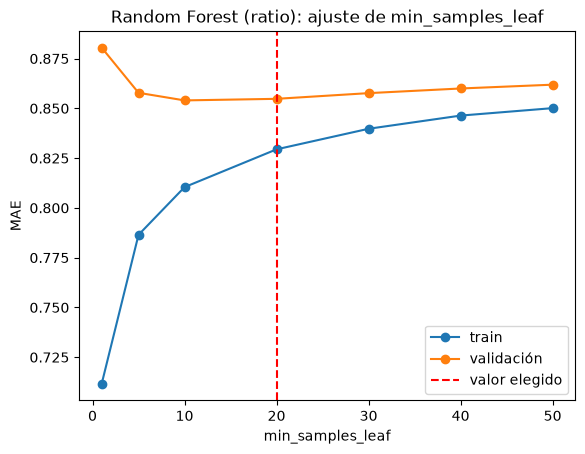

In [62]:
plt.plot(ajuste_rf["min_samples_leaf"], ajuste_rf["MAE_train"], marker="o", label="train")
plt.plot(ajuste_rf["min_samples_leaf"], ajuste_rf["MAE_medio_val"], marker="o", label="validación")
plt.axvline(x=20, color="red", linestyle="--", linewidth=1.5, label="valor elegido")
plt.xlabel("min_samples_leaf")
plt.ylabel("MAE")
plt.title("Random Forest (ratio): ajuste de min_samples_leaf")
plt.legend()
plt.savefig(FIGURES / "13_rf_min_samples_leaf_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

Lo interesante aquí es la curva de validación.

La curva de validación baja claramente entre 1 y 5  y a partir de ahí se mantiene casi plana, con el mínimo en 10–20. La curva de entrenamiento sube con fuerza hasta 10 y después de forma más suave. Las dos curvas se acercan a medida que crecen las hojas.

Con hojas de una sola fase el modelo memoriza el entrenamiento, pero generaliza peor. Casi todo el efecto del hiperparámetro está en evitar ese caso.

## 4. Entrenar y validar en los 3 folds (log(ratio))

In [63]:
ajuste_rf_log = buscar_hiperparametros(modelo_rf, [{"rf__min_samples_leaf": h} for h in HOJAS],
                                       df, MESES_VALIDACION, log=True)
ajuste_rf_log = ajuste_rf_log.rename(columns={"rf__min_samples_leaf": "min_samples_leaf"})
display(ajuste_rf_log.round(3))

,min_samples_leaf,MAE_train,MAE_medio_val,RMSE_medio,MAE_por_fold
0,1,0.684,0.866,1.318,"[0.921, 0.832, 0.845]"
1,5,0.754,0.844,1.304,"[0.902, 0.816, 0.813]"
2,10,0.776,0.843,1.302,"[0.903, 0.819, 0.806]"
3,20,0.793,0.842,1.301,"[0.904, 0.819, 0.802]"
4,30,0.802,0.843,1.301,"[0.907, 0.82, 0.801]"
5,40,0.808,0.845,1.304,"[0.91, 0.822, 0.803]"
6,50,0.812,0.847,1.305,"[0.912, 0.823, 0.805]"


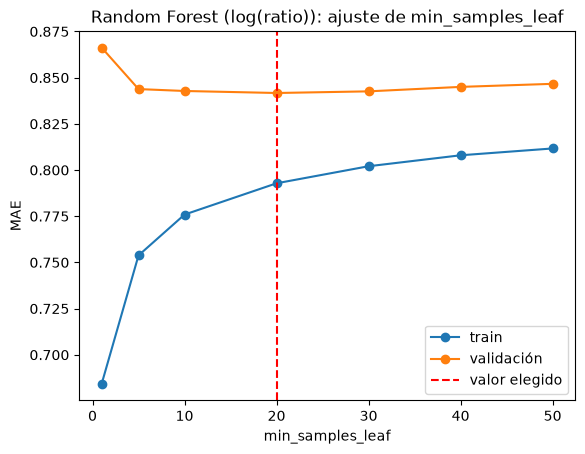

In [64]:
plt.plot(ajuste_rf_log["min_samples_leaf"], ajuste_rf_log["MAE_train"], marker="o", label="train")
plt.plot(ajuste_rf_log["min_samples_leaf"], ajuste_rf_log["MAE_medio_val"], marker="o", label="validación")
plt.axvline(x=20, color="red", linestyle="--", linewidth=1.5, label="valor elegido")
plt.xlabel("min_samples_leaf")
plt.ylabel("MAE")
plt.title("Random Forest (log(ratio)): ajuste de min_samples_leaf")
plt.legend()
plt.savefig(FIGURES / "13_rf_min_samples_leaf_log.png", dpi=200, bbox_inches="tight")
plt.show()

Se repite el mismo patrón que en la versión ratio. El error en validación baja claramente entre 1 y 5 y a partir de
ahí se mantiene casi plano. En validación el mínimo está en 20, que también empata en el menor RMSE.

Con hojas de una sola fase hay sobreajuste: el menor error en entrenamiento y el mayor en validación. La diferencia entre entrenamiento y validación se reduce a medida que crecen las hojas. Febrero sigue siendo el fold con más error.

Se adopta **min_samples_leaf = 20**, el mismo valor que en la versión ratio. Así, la única diferencia entre ambas formulaciones es la variable objetivo.

## 5. Resultados por fold y predicciones de validación

In [65]:
b0 = pd.read_parquet(PREDICTIONS / "b0.parquet")   # predicciones B0

filas = []
for i, mes in enumerate(MESES_VALIDACION):
    _, valid_b0 = obtener_fold(b0, mes)
    m_b0 = metricas(valid_b0["ratio"], valid_b0["pred_B0"])
    filas.append({
        "fold":            mes,
        "MAE_B0":          m_b0["MAE"],
        "MAE_ratio":       resultados_rf.loc[i, "MAE"],
        "MAE_log(ratio)":  resultados_rf_log.loc[i, "MAE"],
        "RMSE_B0":         m_b0["RMSE"],
        "RMSE_ratio":      resultados_rf.loc[i, "RMSE"],
        "RMSE_log(ratio)": resultados_rf_log.loc[i, "RMSE"],
    })

comparacion_rf = pd.DataFrame(filas).set_index("fold")
comparacion_rf.loc["media"] = comparacion_rf.mean()

# Mejora respecto a B0 (%), en MAE
comparacion_rf["mejora_MAE_ratio_%"] = (1 - comparacion_rf["MAE_ratio"] / comparacion_rf["MAE_B0"]) * 100
comparacion_rf["mejora_MAE_log(ratio)_%"] = (1 - comparacion_rf["MAE_log(ratio)"] / comparacion_rf["MAE_B0"]) * 100
comparacion_rf.round(3)

,MAE_B0,MAE_ratio,MAE_log(ratio),RMSE_B0,RMSE_ratio,RMSE_log(ratio),mejora_MAE_ratio_%,mejora_MAE_log(ratio)_%
fold,,,,,,,,
2026-02,1.140,0.913,0.904,1.779,1.302,1.376,19.889,20.648
2026-03,1.086,0.832,0.819,1.672,1.214,1.279,23.388,24.532
2026-04,1.092,0.820,0.802,1.680,1.179,1.247,24.936,26.602
media,1.106,0.855,0.842,1.711,1.231,1.301,22.696,23.880


In [66]:
modelo_rf.set_params(rf__min_samples_leaf=20)

resultados_rf, pred_ratio = evaluar_en_folds(modelo_rf, df, MESES_VALIDACION)
resultados_rf_log, pred_log = evaluar_en_folds(modelo_rf, df, MESES_VALIDACION, log=True)

print("RF ratio\n", resultados_rf.round(3))
display(f"MAE medio {resultados_rf['MAE'].mean():.3f} | RMSE medio {resultados_rf['RMSE'].mean():.3f}")
print("-"*60)
print("\nRF log(ratio)\n", resultados_rf_log.round(3))
display(f"MAE medio {resultados_rf_log['MAE'].mean():.3f} | RMSE medio {resultados_rf_log['RMSE'].mean():.3f}")

RF ratio
           bloque  n_train    MAE   RMSE    n
0  valid 2026-02     8890  0.913  1.302  915
1  valid 2026-03     9805  0.832  1.214  993
2  valid 2026-04    10798  0.820  1.179  963


'MAE medio 0.855 | RMSE medio 1.231'

------------------------------------------------------------

RF log(ratio)
           bloque  n_train    MAE   RMSE    n
0  valid 2026-02     8890  0.904  1.376  915
1  valid 2026-03     9805  0.819  1.279  993
2  valid 2026-04    10798  0.802  1.247  963


'MAE medio 0.842 | RMSE medio 1.301'

Con `min_samples_leaf` = 20 en ambas versiones, log(ratio) obtiene menor MAE en los 3 folds. La ventaja es pequeña, pero consistente. En RMSE ocurre lo contrario: la versión ratio es mejor en los 3 folds.

Las dos métricas no coinciden, igual que en Ridge. La versión log reduce el error en la fase típica, pero comete más
error en las fases con desviaciones grandes.

Como el MAE es la métrica principal, se considera log(ratio) la mejor versión de Random Forest. La transformación logarítmica mantiene su ventaja también en un modelo no lineal.

Se guardan las predicciones de validación de las dos versiones:

In [67]:
pred_rf_valid = pred_ratio.rename(columns={"pred": "pred_rf_ratio"})
pred_rf_valid["pred_rf_log"] = pred_log["pred"].values

pred_rf_valid.to_parquet(PREDICTIONS / "rf_valid.parquet", index=False)
print(pred_rf_valid.shape)

(2871, 5)


## 6. Predicciones de test

Con los hiperparámetros congelados en validación (`min_samples_leaf` = 20), se reentrena con todo el conjunto de
desarrollo y se predice el test. Aquí solo se guardan las predicciones: el test se evalúa una única vez, en el
notebook 15.

In [68]:
desarrollo = df[df["split"] == "desarrollo"]
test = df[df["split"] == "test"]

pred_rf_test = pd.DataFrame({
    "IDMOTask":      test["IDMOTask"].values,
    "mes_orden":     test["mes_orden"].values,
    "ratio":         test[OBJETIVO].values,
    "pred_rf_ratio": ajustar_y_predecir(modelo_rf, desarrollo, test),
    "pred_rf_log":   ajustar_y_predecir(modelo_rf, desarrollo, test, log=True),
})

print(pred_rf_test.shape, pred_rf_test.isna().sum().sum())
pred_rf_test.to_parquet(PREDICTIONS / "rf_test.parquet", index=False)

(2385, 5) 0
